# This notebook performs an analysis of revenue over time between January and June, 2026.

## Start by importing the necessary libraries for analysis

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## Load the sales data

In [16]:
df = pd.read_csv("../data/ecommerce_sales.csv")

### Inspect the data headers

In [17]:
df.head()

,order_id,date,city,category,price,units,revenue
0,100000,2024-04-19,Stockholm,Sports,530.95,4,2123.80
1,100001,2024-05-06,Malmö,Sports,653.28,3,1959.84
2,100002,2024-03-07,Uppsala,Clothing,177.98,4,711.92
3,100003,2024-04-08,Göteborg,Home,348.57,3,1045.71
4,100004,2024-01-18,Uppsala,Electronics,777.07,3,2331.21


### Let's also inspect what the data types are

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   order_id  2500 non-null   int64  
 1   date      2500 non-null   str    
 2   city      2500 non-null   str    
 3   category  2500 non-null   str    
 4   price     2500 non-null   float64
 5   units     2500 non-null   int64  
 6   revenue   2500 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 136.8 KB


### Since column "date" is a string, we need to convert its data type

In [19]:
df["date"] = pd.to_datetime(df["date"])
print(df["date"].dtype)
print("First date:", df["date"].min())
print("Last date:", df["date"].max())

datetime64[us]
First date: 2024-01-01 00:00:00
Last date: 2024-06-30 00:00:00


## Initial data exploration showed that daily resolution became too noisy. As such, we will sum revenues per week.

In [20]:
weekly_revenue = (
    df.groupby(pd.Grouper(key="date", freq="W"))["revenue"]
    .sum()
    .reset_index()
)

weekly_revenue.head()

,date,revenue
0,2024-01-07,161119.04
1,2024-01-14,136568.68
2,2024-01-21,147225.11
3,2024-01-28,165832.80
4,2024-02-04,124154.34


## Plot the weekly revenues for visual inspection

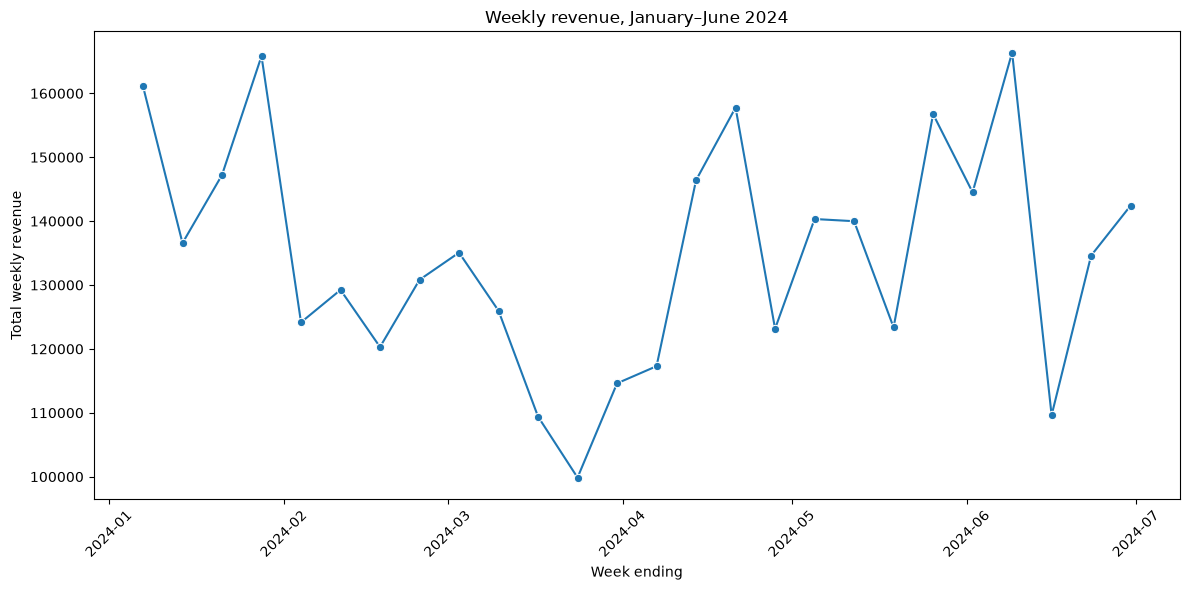

In [21]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_revenue,
    x="date",
    y="revenue",
    marker="o"
)

plt.xlabel("Week ending")
plt.ylabel("Total weekly revenue")
plt.title("Weekly revenue, January–June 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretation

Weekly revenue is generally lower in February and March than in January, with a minimum around mid-March. Revenue recovers sharply in April but continues to fluctuate substantially through June, without a consistent upward trend.

## Now, we will explore what weekly revenue patterns emerge for each product category. Let's start by suming the revenues.

In [22]:
weekly_category = (
    df.groupby(["category", pd.Grouper(key="date", freq="W")])["revenue"]
    .sum()
    .reset_index()
)

weekly_category.head()

,category,date,revenue
0,Beauty,2024-01-07,10994.38
1,Beauty,2024-01-14,3607.16
2,Beauty,2024-01-21,12456.01
3,Beauty,2024-01-28,6584.77
4,Beauty,2024-02-04,3654.09


# Plot the results.

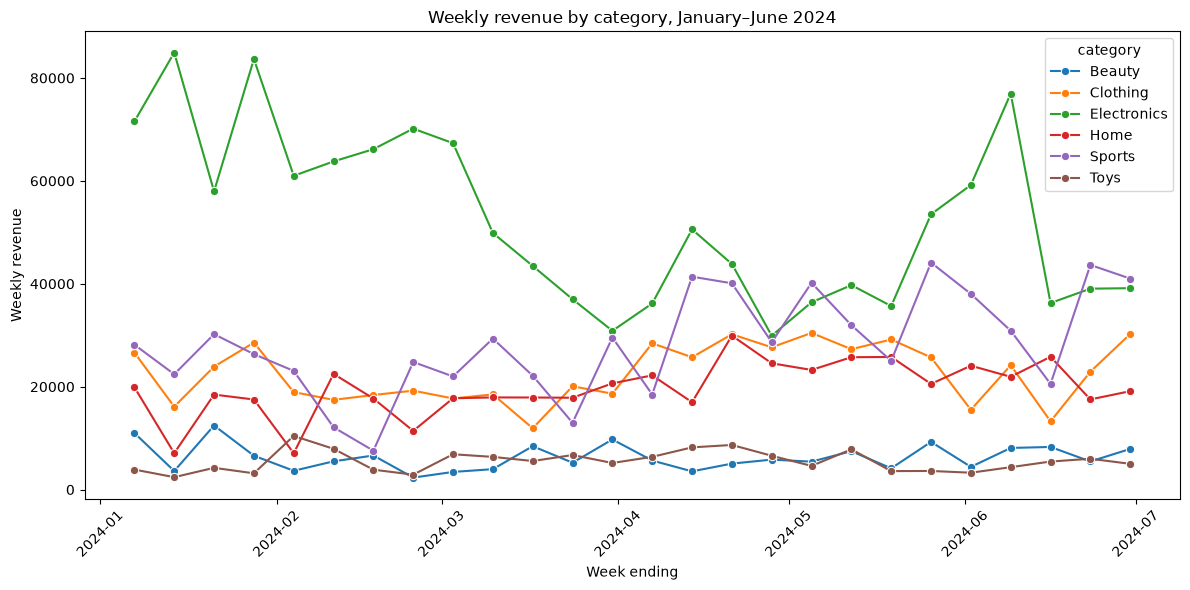

In [23]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_category,
    x="date",
    y="revenue",
    hue="category",
    marker="o"
)

plt.xlabel("Week ending")
plt.ylabel("Weekly revenue")
plt.title("Weekly revenue by category, January–June 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretation
The category electronics demonstrate the largest absolute revenue decline during March and contributes the most to a dip in total weekly revenues. A recovery in April also coincides with increased revenues in the category sports, indicating that revenues across categories exhibits different patterns over time.

## Weekly units sold by category
Weekly units sold were analysed to investigate whether changes in revenue coincide with changes in sales volume. Comparing units and revenue by category helps distinguish changes in the quantity sold from changes in average revenue per unit.

### Let's start by summing the number of units per week

In [24]:
weekly_units = (
    df.groupby(["category", pd.Grouper(key="date", freq="W")])["units"]
    .sum()
    .reset_index()
)

weekly_units.head()

,category,date,units
0,Beauty,2024-01-07,35
1,Beauty,2024-01-14,20
2,Beauty,2024-01-21,48
3,Beauty,2024-01-28,23
4,Beauty,2024-02-04,18


## Now plot the results

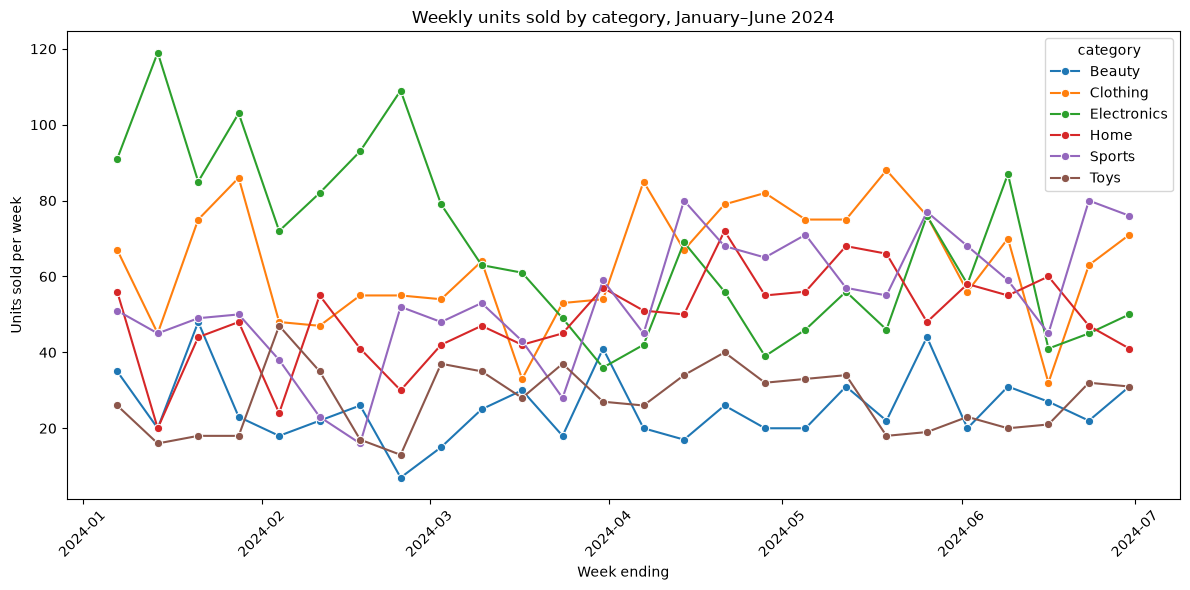

In [25]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_units,
    x="date",
    y="units",
    hue="category",
    marker="o"
)

plt.xlabel("Week ending")
plt.ylabel("Units sold per week")
plt.title("Weekly units sold by category, January–June 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretation
Electronics units sold decline through March, broadly matching the category’s revenue decline. Sports units increase sharply in April, suggesting that higher sales volume contributes to its increased revenue during that period.

## Weekly average revenue per unit by category
Finally, we will calculate the average revenue per unit by dividing each category’s total weekly revenue with the total weekly units sold. Comparing this metric with revenue and sales volume helps assess whether fluctuations in revenue reflect changes in quantities sold or changes in the average revenue earned per item.

In [26]:
weekly_category_metrics = (
    df.groupby(["category", pd.Grouper(key="date", freq="W")])
    [["revenue", "units"]]
    .sum()
    .reset_index()
)

# Check that every denominator is positive
assert (weekly_category_metrics["units"] > 0).all(), (
    "Weekly units must be positive to calculate revenue per unit."
)

# Calculate average revenue per unit
weekly_category_metrics["revenue_per_unit"] = (
    weekly_category_metrics["revenue"]
    / weekly_category_metrics["units"]
)

weekly_category_metrics.head()

,category,date,revenue,units,revenue_per_unit
0,Beauty,2024-01-07,10994.38,35,314.125143
1,Beauty,2024-01-14,3607.16,20,180.358000
2,Beauty,2024-01-21,12456.01,48,259.500208
3,Beauty,2024-01-28,6584.77,23,286.294348
4,Beauty,2024-02-04,3654.09,18,203.005000


## Plot the results

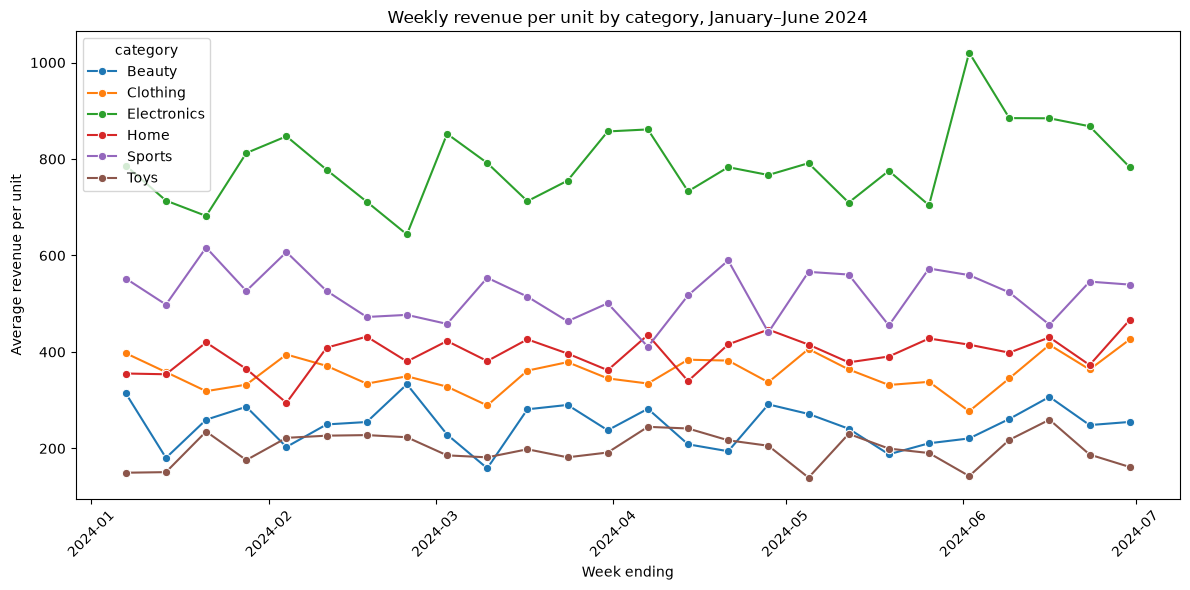

In [27]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_category_metrics,
    x="date",
    y="revenue_per_unit",
    hue="category",
    marker="o"
)

plt.xlabel("Week ending")
plt.ylabel("Average revenue per unit")
plt.title("Weekly revenue per unit by category, January–June 2024")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretation
Electronics revenue and units sold both decline during March, while average revenue per unit shows no sustained decline. This suggests that reduced sales volume is the main contributor to the category’s revenue decrease during this period.

## Conclusion

Weekly revenues appear to fluctuate substantially during January–June 2024, with lower levels in February and March and a recovery in April. Electronics drive declines in revenue most markedly, while increased revenue in sports items accompanies the recovery in April.

The decline in Electronics revenue seems to coincide with fewer units sold, albeit without a sustained decline in average revenue per unit. This suggests that reduced sales volume is the main contributor to its revenue decrease. That said, this study covers only a six-month observational window, thus limiting the analysis ability to unveil potential patterns such recurring and annual seasonality. Furthermore, the present study did also not have access to any data pertaining to consumers, such as purchasing power and so forth. By gathering more data points for the remaining two sales quarters, as well as customer data, a deeper analysis could potentially point toward causes and actions to boost revenues.   

## Recomendations

- Investigate the March decline in Electronics sales using additional forms of consumer data.
- Review the increase in Sports sales during April to inform future stock and marketing planning.
- Collect additional years of data before making decisions based on presumed annual seasonal patterns.